In [1]:
import time
import tracemalloc
import random
import matplotlib.pyplot as plt

print("AAD Algorithm Analysis")
print("Environment ready!")

AAD Algorithm Analysis
Environment ready!


In [2]:
def bubble_sort(arr):
    n = len(arr)

    for i in range(n):
        swapped = False

        for j in range(0, n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
                swapped = True

        if not swapped:
            break

    return arr


# Test
arr = [64, 34, 25, 12, 22, 11, 90]

print("Original Array:", arr)
print("Sorted Array:", bubble_sort(arr.copy()))

Original Array: [64, 34, 25, 12, 22, 11, 90]
Sorted Array: [11, 12, 22, 25, 34, 64, 90]


In [3]:
def selection_sort(arr):
    n = len(arr)

    for i in range(n):
        min_index = i

        for j in range(i + 1, n):
            if arr[j] < arr[min_index]:
                min_index = j

        arr[i], arr[min_index] = arr[min_index], arr[i]

    return arr


# Test
arr = [64, 25, 12, 22, 11]

print("Original Array:", arr)
print("Sorted Array:", selection_sort(arr.copy()))

Original Array: [64, 25, 12, 22, 11]
Sorted Array: [11, 12, 22, 25, 64]


In [4]:
def merge_sort(arr):

    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2

    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    return merge(left, right)


def merge(left, right):

    result = []
    i = 0
    j = 0

    while i < len(left) and j < len(right):

        if left[i] <= right[j]:
            result.append(left[i])
            i += 1

        else:
            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


# Test
arr = [38, 27, 43, 3, 9, 82, 10]

print("Original Array:", arr)
print("Sorted Array:", merge_sort(arr))


Original Array: [38, 27, 43, 3, 9, 82, 10]
Sorted Array: [3, 9, 10, 27, 38, 43, 82]


In [5]:
def quick_sort(arr):

    if len(arr) <= 1:
        return arr

    pivot = arr[len(arr) // 2]

    left = [x for x in arr if x < pivot]
    middle = [x for x in arr if x == pivot]
    right = [x for x in arr if x > pivot]

    return quick_sort(left) + middle + quick_sort(right)


# Test
arr = [10, 7, 8, 9, 1, 5]

print("Original Array:", arr)
print("Sorted Array:", quick_sort(arr))

Original Array: [10, 7, 8, 9, 1, 5]
Sorted Array: [1, 5, 7, 8, 9, 10]


In [6]:
def recursive_fibonacci(n):

    if n <= 1:
        return n

    return recursive_fibonacci(n - 1) + recursive_fibonacci(n - 2)


# Test
n = 10

print("Recursive Fibonacci")
print("n =", n)
print("Result =", recursive_fibonacci(n))

Recursive Fibonacci
n = 10
Result = 55


In [7]:
def iterative_fibonacci(n):

    a, b = 0, 1

    for i in range(n):
        a, b = b, a + b

    return a


# Test
n = 10

print("Iterative Fibonacci")
print("n =", n)
print("Result =", iterative_fibonacci(n))

Iterative Fibonacci
n = 10
Result = 55


In [8]:
def fibonacci_memo(n):

    memo = {}

    def fib(n):

        if n <= 1:
            return n

        if n in memo:
            return memo[n]

        memo[n] = fib(n - 1) + fib(n - 2)

        return memo[n]

    return fib(n)


# Test
n = 10

print("Memoization Fibonacci")
print("n =", n)
print("Result =", fibonacci_memo(n))

Memoization Fibonacci
n = 10
Result = 55


In [9]:
import pandas as pd
import time
import tracemalloc
import random


# -----------------------------------
# Experimental Analysis Function
# -----------------------------------

def measure_performance(sort_function, data):
    """
    Measures execution time and memory usage
    of a sorting algorithm.
    """

    arr = data.copy()

    # Start memory tracking
    tracemalloc.start()

    # Start time
    start_time = time.perf_counter()

    # Run sorting algorithm
    sort_function(arr)

    # End time
    end_time = time.perf_counter()

    # Get memory information
    current, peak = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    execution_time = end_time - start_time

    # Convert memory from bytes to KB
    memory_usage = peak / 1024

    return execution_time, memory_usage


# -----------------------------------
# Sorting Algorithms
# -----------------------------------

algorithms = {
    "Bubble Sort": bubble_sort,
    "Selection Sort": selection_sort,
    "Merge Sort": merge_sort,
    "Quick Sort": quick_sort
}


# -----------------------------------
# Input Sizes
# -----------------------------------

input_sizes = [100, 500, 1000, 2000, 5000]


# -----------------------------------
# Experimental Analysis
# -----------------------------------

results = []

for size in input_sizes:

    # Random data
    random_data = random.sample(range(size * 10), size)

    # Sorted data
    sorted_data = sorted(random_data)

    # Reverse-sorted data
    reverse_data = sorted(random_data, reverse=True)

    datasets = {
        "Sorted": sorted_data,
        "Reverse Sorted": reverse_data,
        "Random": random_data
    }

    for condition, data in datasets.items():

        for algorithm_name, algorithm in algorithms.items():

            time_taken, memory_used = measure_performance(
                algorithm,
                data
            )

            results.append({
                "Algorithm": algorithm_name,
                "Input Size": size,
                "Condition": condition,
                "Execution Time (seconds)": time_taken,
                "Memory Usage (KB)": memory_used
            })


# -----------------------------------
# Create Result Table
# -----------------------------------

results_df = pd.DataFrame(results)

print("EXPERIMENTAL ANALYSIS RESULTS")
print("=" * 80)

display(results_df)

EXPERIMENTAL ANALYSIS RESULTS


,Algorithm,Input Size,Condition,Execution Time (seconds),Memory Usage (KB)
0,Bubble Sort,100,Sorted,0.000021,0.125000
1,Selection Sort,100,Sorted,0.000419,0.125000
2,Merge Sort,100,Sorted,0.000749,2.695312
3,Quick Sort,100,Sorted,0.000675,3.132812
4,Bubble Sort,100,Reverse Sorted,0.000845,0.125000
5,Selection Sort,100,Reverse Sorted,0.000456,0.125000
6,Merge Sort,100,Reverse Sorted,0.000782,1.984375
7,Quick Sort,100,Reverse Sorted,0.000573,2.742188
8,Bubble Sort,100,Random,0.001267,0.125000
9,Selection Sort,100,Random,0.000439,0.125000


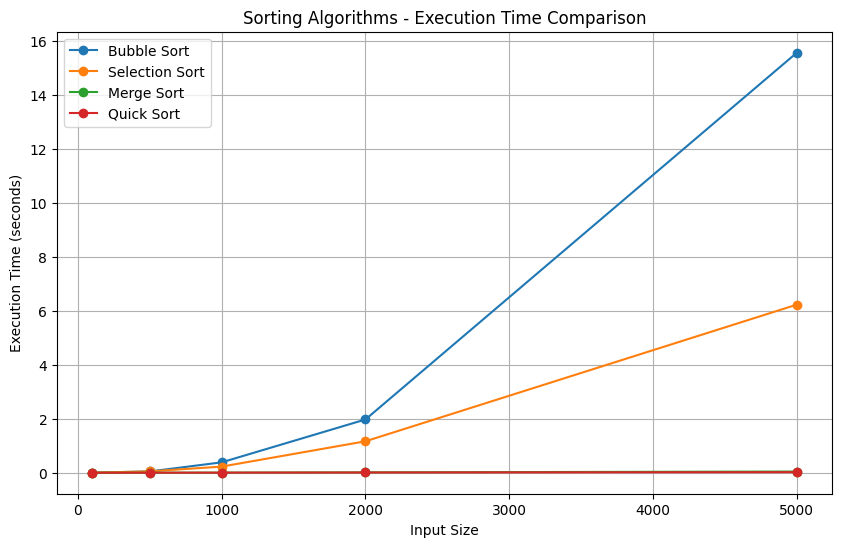

In [10]:
import matplotlib.pyplot as plt

# -----------------------------------
# Execution Time Comparison
# -----------------------------------

plt.figure(figsize=(10, 6))

for algorithm in results_df["Algorithm"].unique():

    data = results_df[results_df["Algorithm"] == algorithm]

    # Average time for each input size
    avg_time = data.groupby("Input Size")["Execution Time (seconds)"].mean()

    plt.plot(
        avg_time.index,
        avg_time.values,
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Sorting Algorithms - Execution Time Comparison")
plt.legend()
plt.grid(True)

plt.show()

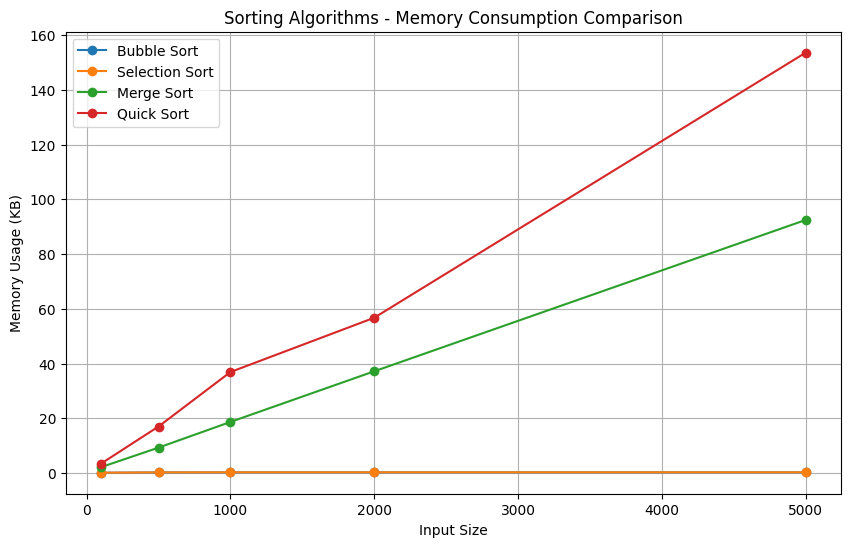

In [11]:
# -----------------------------------
# Memory Consumption Comparison
# -----------------------------------

plt.figure(figsize=(10, 6))

for algorithm in results_df["Algorithm"].unique():

    data = results_df[results_df["Algorithm"] == algorithm]

    # Average memory for each input size
    avg_memory = data.groupby("Input Size")["Memory Usage (KB)"].mean()

    plt.plot(
        avg_memory.index,
        avg_memory.values,
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Memory Usage (KB)")
plt.title("Sorting Algorithms - Memory Consumption Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
# ==========================================
# Fibonacci Experimental Analysis
# ==========================================

def measure_fibonacci(fib_function, n):
    """
    Measures execution time and memory usage
    of a Fibonacci algorithm.
    """

    tracemalloc.start()

    start_time = time.perf_counter()

    result = fib_function(n)

    end_time = time.perf_counter()

    current, peak = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    execution_time = end_time - start_time
    memory_usage = peak / 1024   # Convert bytes to KB

    return result, execution_time, memory_usage


# Fibonacci algorithms
fibonacci_algorithms = {
    "Recursive Fibonacci": recursive_fibonacci,
    "Iterative Fibonacci": iterative_fibonacci,
    "Memoization Fibonacci": fibonacci_memo
}


# Input sizes
# Recursive Fibonacci is intentionally kept at 30
# because its execution grows very quickly.
fibonacci_sizes = [5, 10, 15, 20, 25, 30]


# Store results
fibonacci_results = []

for n in fibonacci_sizes:

    for algorithm_name, algorithm in fibonacci_algorithms.items():

        result, execution_time, memory_used = measure_fibonacci(
            algorithm, n
        )

        fibonacci_results.append({
            "Algorithm": algorithm_name,
            "Input Size": n,
            "Fibonacci Value": result,
            "Execution Time (seconds)": execution_time,
            "Memory Usage (KB)": memory_used
        })


# Create DataFrame
fibonacci_df = pd.DataFrame(fibonacci_results)

print("FIBONACCI EXPERIMENTAL ANALYSIS RESULTS")
print("=" * 80)

display(fibonacci_df)

FIBONACCI EXPERIMENTAL ANALYSIS RESULTS


,Algorithm,Input Size,Fibonacci Value,Execution Time (seconds),Memory Usage (KB)
0,Recursive Fibonacci,5,5,0.000002,0.000000
1,Iterative Fibonacci,5,5,0.000004,0.085938
2,Memoization Fibonacci,5,5,0.000028,0.390625
3,Recursive Fibonacci,10,55,0.000013,0.000000
4,Iterative Fibonacci,10,55,0.000003,0.085938
5,Memoization Fibonacci,10,55,0.000010,0.671875
6,Recursive Fibonacci,15,610,0.000101,0.062500
7,Iterative Fibonacci,15,610,0.000004,0.132812
8,Memoization Fibonacci,15,610,0.000011,1.070312
9,Recursive Fibonacci,20,6765,0.001287,1.100586


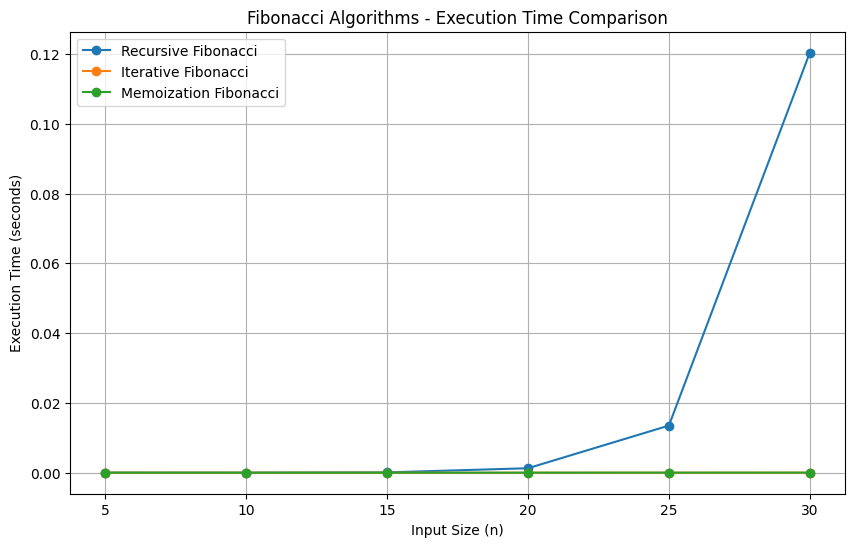

In [13]:
# ==========================================
# Fibonacci - Execution Time Comparison
# ==========================================

plt.figure(figsize=(10, 6))

for algorithm in fibonacci_df["Algorithm"].unique():

    data = fibonacci_df[
        fibonacci_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Fibonacci Algorithms - Execution Time Comparison")
plt.legend()
plt.grid(True)

plt.show()

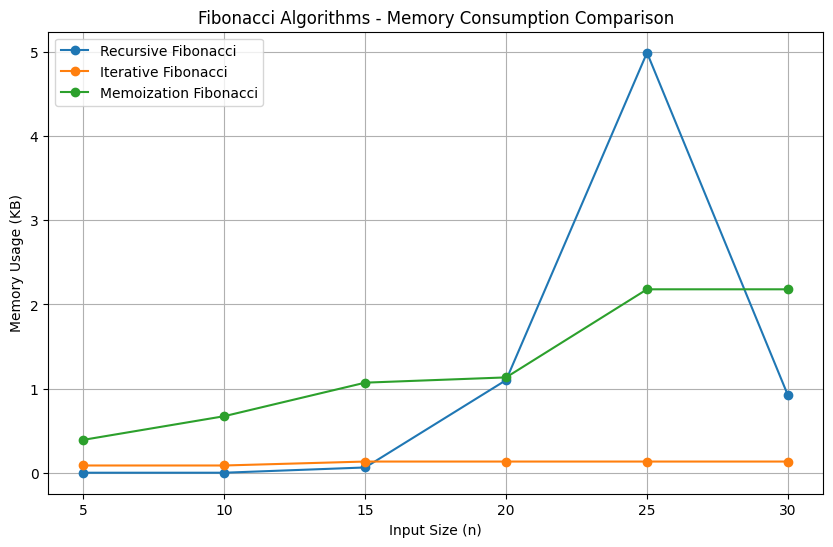

In [14]:
# ==========================================
# Fibonacci - Memory Consumption Comparison
# ==========================================

plt.figure(figsize=(10, 6))

for algorithm in fibonacci_df["Algorithm"].unique():

    data = fibonacci_df[
        fibonacci_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Memory Usage (KB)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size (n)")
plt.ylabel("Memory Usage (KB)")
plt.title("Fibonacci Algorithms - Memory Consumption Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [15]:
# ==========================================
# Complexity Comparison Table
# ==========================================

complexity_data = {
    "Algorithm": [
        "Bubble Sort",
        "Selection Sort",
        "Merge Sort",
        "Quick Sort",
        "Recursive Fibonacci",
        "Iterative Fibonacci",
        "Memoization Fibonacci"
    ],

    "Best Case": [
        "O(n)",
        "O(n²)",
        "O(n log n)",
        "O(n log n)",
        "O(2ⁿ)",
        "O(n)",
        "O(n)"
    ],

    "Average Case": [
        "O(n²)",
        "O(n²)",
        "O(n log n)",
        "O(n log n)",
        "O(2ⁿ)",
        "O(n)",
        "O(n)"
    ],

    "Worst Case": [
        "O(n²)",
        "O(n²)",
        "O(n log n)",
        "O(n²)",
        "O(2ⁿ)",
        "O(n)",
        "O(n)"
    ],

    "Space Complexity": [
        "O(1)",
        "O(1)",
        "O(n)",
        "O(log n)*",
        "O(n)",
        "O(1)",
        "O(n)"
    ]
}

complexity_df = pd.DataFrame(complexity_data)

print("COMPLEXITY COMPARISON TABLE")
print("=" * 80)

display(complexity_df)

print("* Quick Sort space complexity may vary depending on pivot selection and implementation.")

COMPLEXITY COMPARISON TABLE


,Algorithm,Best Case,Average Case,Worst Case,Space Complexity
0,Bubble Sort,O(n),O(n²),O(n²),O(1)
1,Selection Sort,O(n²),O(n²),O(n²),O(1)
2,Merge Sort,O(n log n),O(n log n),O(n log n),O(n)
3,Quick Sort,O(n log n),O(n log n),O(n²),O(log n)*
4,Recursive Fibonacci,O(2ⁿ),O(2ⁿ),O(2ⁿ),O(n)
5,Iterative Fibonacci,O(n),O(n),O(n),O(1)
6,Memoization Fibonacci,O(n),O(n),O(n),O(n)


* Quick Sort space complexity may vary depending on pivot selection and implementation.
